#### **Настройка ноутбука**

In [2]:
import os

import numpy as np
import pandas as pd

import requests

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px
import plotly.io as pio

pio.renderers.default = "png"
pio.templates.default = "plotly_white"

from dotenv import load_dotenv

In [3]:
load_dotenv()

CORE_PATH = os.getenv("CORE_PATH")
if not CORE_PATH:
    raise ValueError("Не найден CORE_PATH в файле .env")

DATA_PATH = os.path.join(CORE_PATH, "data")

SCRIPTS_PATH = os.path.join(CORE_PATH, "scripts")

DATASET_PATH = os.path.join(DATA_PATH, "VK_dataset.parquet")

#### **Разведывательный анализ данных датасета** 

##### **Первый взгляд на датасет**

In [4]:
df = pd.read_parquet(DATASET_PATH, engine='pyarrow')

In [5]:
df.head(3)

,id,search_query,city,region,source_type,date,author_link,link,text,text_char_count,...,text_emoji_count,text_digit_count,text_punctuation_count,text_uppercase_ratio,text_has_question,text_has_exclamation,text_is_uppercase,text_has_url,text_has_hashtag,text_has_emoji
0,-226976538_46733,рабочий дом Абакан,Абакан,Республика Хакасия,newsfeed,2026-11-13,https://vk.com/public226976538,https://vk.com/wall-226976538_46733,Желающих купить скандальный недострой в с.Прии...,3195,...,0,83,129,0.040744,1,0,0,1,0,0
1,-149834701_52521,рабочий дом Абакан,Абакан,Республика Хакасия,newsfeed,2026-11-13,https://vk.com/public149834701,https://vk.com/wall-149834701_52521,"Пятница, тринадцатое. Инструкция по выживанию ...",1585,...,1,0,80,0.028158,1,0,0,1,0,1
2,-109001977_3630,рабочий дом Абакан,Абакан,Республика Хакасия,newsfeed,2026-11-13,https://vk.com/public109001977,https://vk.com/wall-109001977_3630,🏗Росреестр Хакасии поставил на кадастровый уче...,2055,...,9,40,73,0.033013,0,0,0,0,1,1


Как видно по выводу, у нас есть 30 признаков, которые мы в дальнейшем анализе поделим на две категории: 
- **первичные** (полученные при составлении датасета из ВК или таблицы с городами): *city, region, source_type, date, author_link, link, text*
- **текстовые** (полученные из анализа символов в тексте): *остальные признаки*

In [6]:
df.shape

(8774, 30)

В нашем датасете 8774 поста. Рассмотрим представленность данных по каждому из признаков.

In [7]:
df.notna().sum()

id                          8774
search_query                8774
city                        8774
region                      8774
source_type                 8774
date                        8774
author_link                 8774
link                        8774
text                        8774
text_char_count             8774
text_word_count             8774
text_sentence_count         8774
text_paragraph_count        8774
text_avg_word_length        8774
text_avg_sentence_length    8774
text_unique_words           8774
text_unique_word_ratio      8774
text_url_count              8774
text_hashtag_count          8774
text_mention_count          8774
text_emoji_count            8774
text_digit_count            8774
text_punctuation_count      8774
text_uppercase_ratio        8774
text_has_question           8774
text_has_exclamation        8774
text_is_uppercase           8774
text_has_url                8774
text_has_hashtag            8774
text_has_emoji              8774
dtype: int

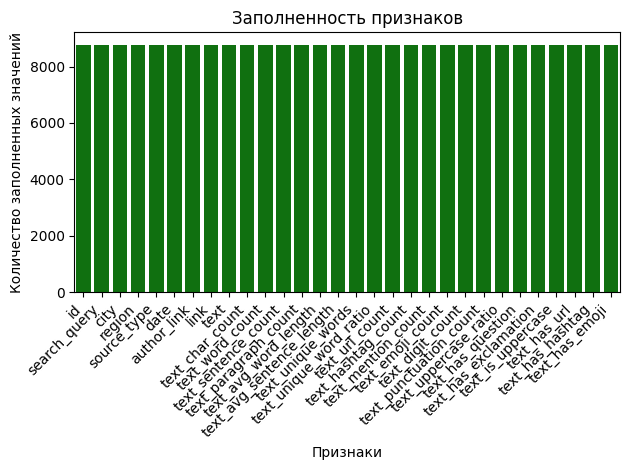

In [8]:
sns.barplot(x = df.columns,
            y = df.notna().sum(), 
            color="green")

plt.xticks(rotation=45, ha="right")
plt.xlabel("Признаки")
plt.ylabel("Количество заполненных значений")
plt.title("Заполненность признаков")
plt.tight_layout()
plt.show()

По диаграмме видно, что во всех столбцах присуствуют во всех столбцах в полном объёме, что означает, что ВК-парсер и текстовый парсер что-то написали в каждую ячейку. Однако качество этих данных требует проверки, которая будет проведена далее в ноутбуке.

##### **Анализ первичных признаков**

Первым и самым важным для анализа географической представленности рабдомов являются город и регион. Посмотрим, каким образом у нас распределены посты по регионам.

In [9]:
region_counts = df['region'].value_counts().reset_index()
region_counts

,region,count
0,Московская область,1050
1,Ростовская область,372
2,Ставропольский край,298
3,Республика Башкортостан,253
4,Челябинская область,250
...,...,...
80,Калининградская область,28
81,Смоленская область,27
82,Рязанская область,23
83,Тверская область,23


Однако такую таблицу неудобно анализировать, поэтому попробуем визуализировать данные на карте

In [10]:
geojson_url = "https://raw.githubusercontent.com/codeforamerica/click_that_hood/master/public/data/russia.geojson"
russia_geojson = requests.get(geojson_url).json()

In [11]:
def draw_the_map(region_counts):
    fig = px.choropleth(
    region_counts,
    geojson = russia_geojson,
    locations = 'region',
    featureidkey = 'properties.name',
    color = 'count',
    color_continuous_scale = "Reds", 
    range_color = (0, region_counts['count'].max()),
    hover_name = 'region',
    )

    fig.update_geos(
        visible = False, 
        fitbounds = "locations", 
        lataxis_range = [40, 80], # Ограничиваем широту
        lonaxis_range = [20, 190], # Ограничиваем долготу
        # center = dict(lat = 60, lon = 100)
    )

    fig.update_layout(
        width = 1000,
        height = 800,
        coloraxis_colorbar = dict(
            thicknessmode = "pixels", thickness = 8, 
            lenmode = "fraction", len = 0.2,
            yanchor = "middle", y = 0.2,
            ticks = "outside"
        )
    )

    fig.update_traces(marker_line_width = 0.5, marker_line_color = "white")

    fig.show()

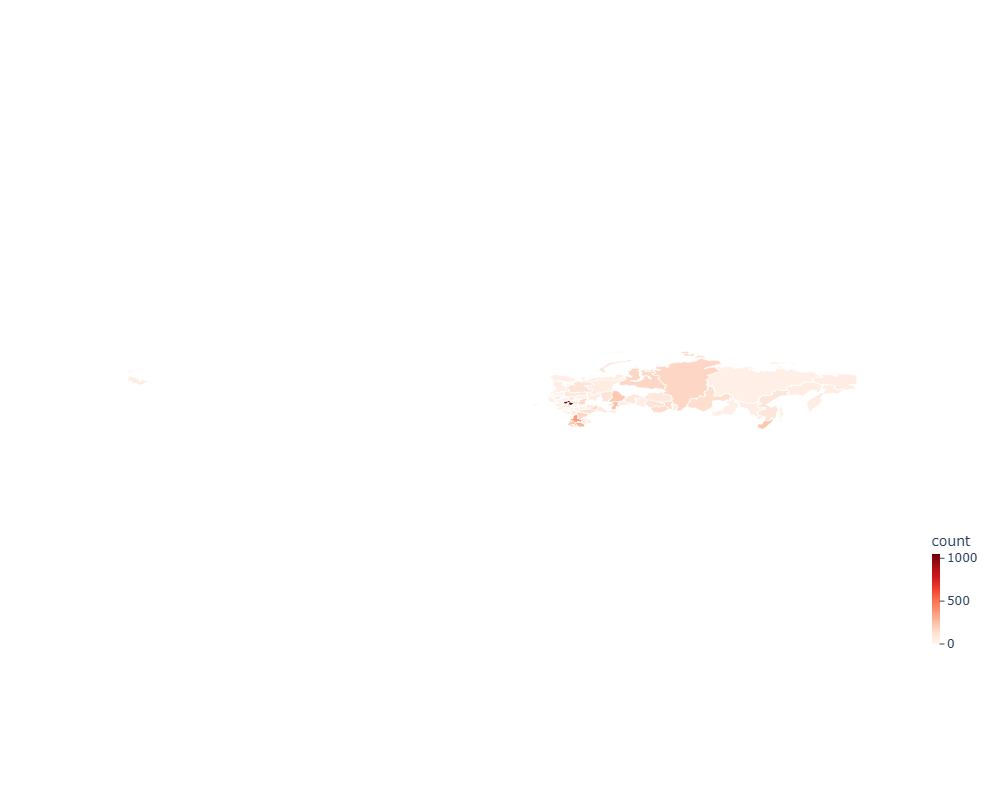

In [12]:
draw_the_map(region_counts)

Заметим (или, по крайней мере, попытаемся заметить), что у нас неравномерно распределены посты по регионам - больше всего их в Москве, также их повышенное количество в южных регионах Европейской части; и при этом несколько центральных регионов почти "выпадают"

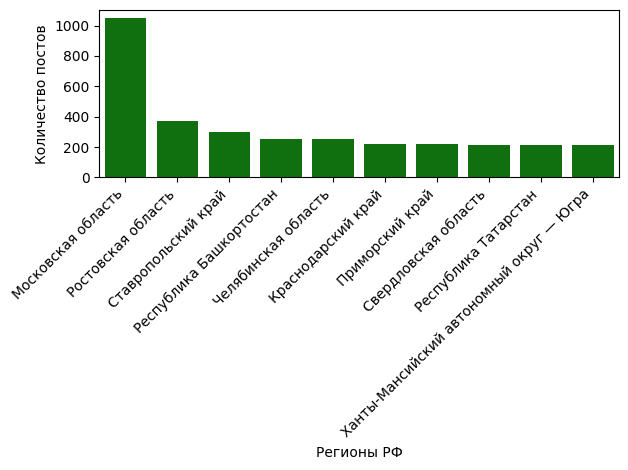

In [13]:
sns.barplot(x = region_counts["region"][:10],
            y = region_counts["count"], 
            color="green")

plt.xticks(rotation=45, ha="right")
plt.xlabel("Регионы РФ")
plt.ylabel("Количество постов")
plt.tight_layout()
plt.show()

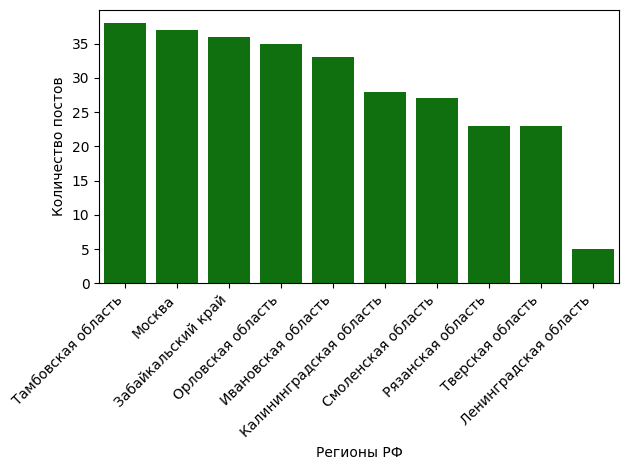

In [15]:
sns.barplot(x = region_counts["region"][-10:],
            y = region_counts["count"], 
            color="green")

plt.xticks(rotation=45, ha="right")
plt.xlabel("Регионы РФ")
plt.ylabel("Количество постов")
plt.tight_layout()
plt.show()

Стоит отметить, что на данный момент города и регионы для постов записаны на основании запроса, который мы отправляли в ВК. 

Это является проблемой, т.к. в случае запроса *"рабочий дом ***название маленького города***"* мы можем ожидать, что в выдаче будут представлены посты из других городов и, что критичнее, регионов. (Такой вывод мы делаем на основе того, что предполагаем зашитой в поисковик ВК рекомендательной системы, использующей семантический анализ постов.)

Поэтому одним из первых этапов дальнейшего анализа является анализ уникальности по признакам *author_link, link, text*

In [16]:
print("Количество уникальных авторов (людей или пабликов) постов:", len(df["author_link"].unique()))
print("Количество уникальных ссылок на пост:", len(df["link"].unique()))
print("Количество уникальных текстов:", len(df["text"].unique()))

Количество уникальных авторов (людей или пабликов) постов: 4685
Количество уникальных ссылок на пост: 8774
Количество уникальных текстов: 7297


Интересно, что количество уникальных ссылок на пост у нас совпадает с количеством записей - то есть все посты уникальны. 

Однако также мы видим, что:
- уникальных авторов у нас почти в 2 раза меньше: это может быть объясняться тем, что один автор может публиковать несколько постов по одной тематике (*Прим. автора*: в ВК существуют отдельные паблики, посвящённые объявлениям о местах в рабочих домах);
- уникальных текстов меньше, чем постов: это может говорить либо о публикации одним автором в разное время, либо о публикации одного текста разными авторами.

Предположим, что ключевым ID рабдома (или его человека, его представляющего) является *author_link*, тогда для дальнейшего анализа потребуется фильтрация по данному признаку (а при более глубоком анализе - отдельное исследование кейсов, где одному автору соответствует несколько постов) с удалением всех авторов 2+ постов, тогда мы получим: 

In [17]:
df_dedupled = df.drop_duplicates(subset=["author_link"], keep = False)
df_dedupled.shape

(3981, 30)

Как мы видим, у нас есть 3981 автор, которые написали ровно 1 пост, что означает, что 4685 - 3981 = 704 автора написали 2+ поста (однако в данном EDA мы их, к сожалению, не рассмотрим).

Теперь интересно рассмотреть, в каком количестве регионов представлены уникальные авторы с одним постом:

In [18]:
len(df_dedupled['region'].unique())

85

Очень клёво, что у нас представлены все регионы, однако ещё интересен вопрос: поменялось ли количество постов для каждого региона?

In [19]:
region_counts_dedupled = df_dedupled['region'].value_counts().reset_index()

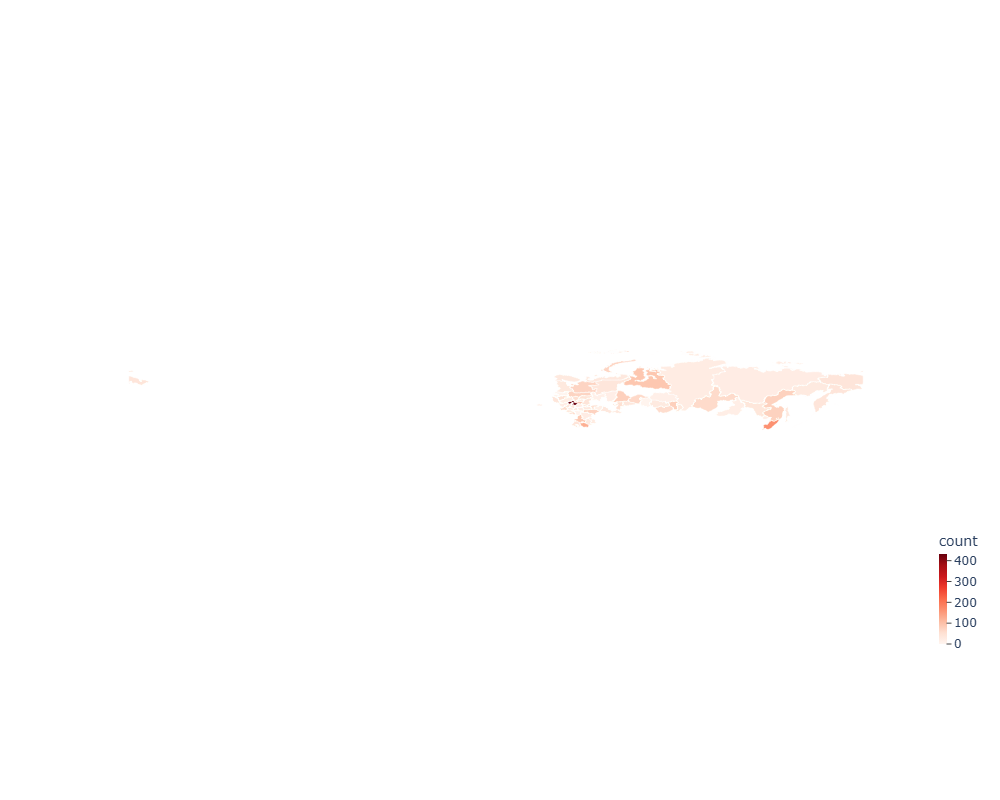

In [20]:
draw_the_map(region_counts_dedupled)

По иллюстрации можно заметить общее уменьшение кол-ва постов на регион, однако оценить влияние фильтрации на представленность регионов в датасете. Для того, чтобы это исправить, проиллюстрируем изменение в количестве постов по регионов после фильтрации

In [21]:
difference = pd.DataFrame()
difference["region"] = region_counts["region"]
difference["count"] = region_counts["count"] - region_counts_dedupled["count"]

difference

,region,count
0,Московская область,618
1,Ростовская область,208
2,Ставропольский край,173
3,Республика Башкортостан,129
4,Челябинская область,159
...,...,...
80,Калининградская область,15
81,Смоленская область,20
82,Рязанская область,19
83,Тверская область,20


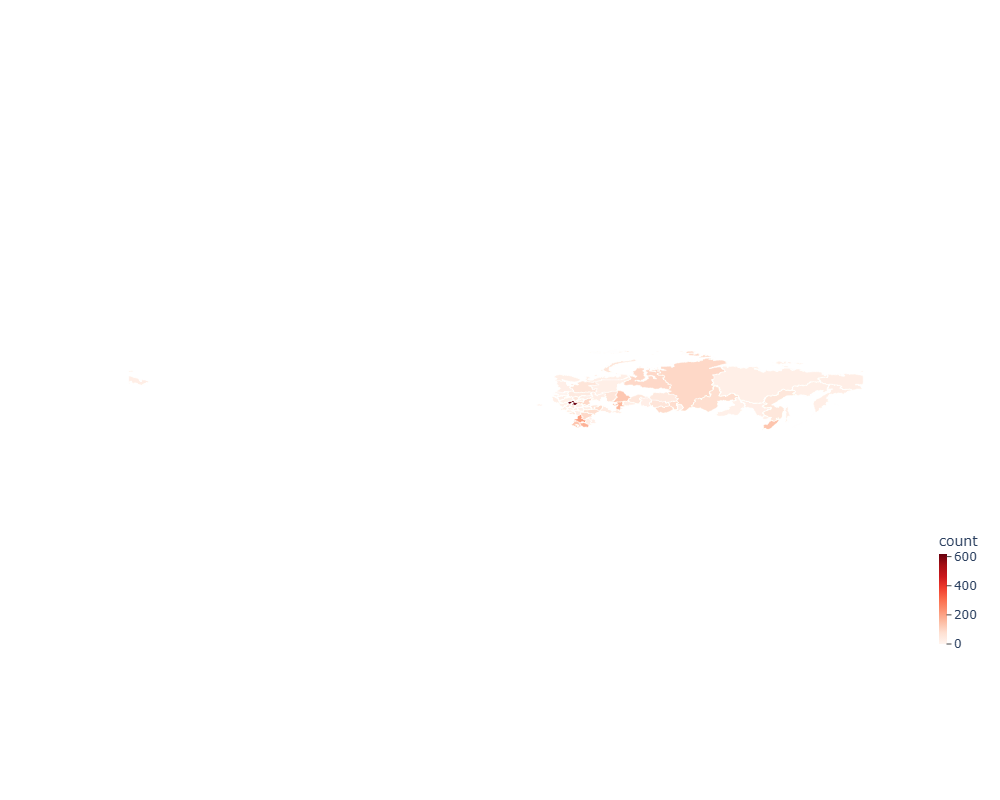

In [22]:
draw_the_map(difference)

Интересно, что изменение в количестве постов имеет похожую окраску на предыдущие карты - поэтому, возможно, имеет смысл рассмотреть относительное изменение количества постов

In [23]:
fold_change = pd.DataFrame()
fold_change["region"] = region_counts["region"]
fold_change["count"] = region_counts["count"] / region_counts_dedupled["count"]

fold_change

,region,count
0,Московская область,2.430556
1,Ростовская область,2.268293
2,Ставропольский край,2.384
3,Республика Башкортостан,2.040323
4,Челябинская область,2.747253
...,...,...
80,Калининградская область,2.153846
81,Смоленская область,3.857143
82,Рязанская область,5.75
83,Тверская область,7.666667


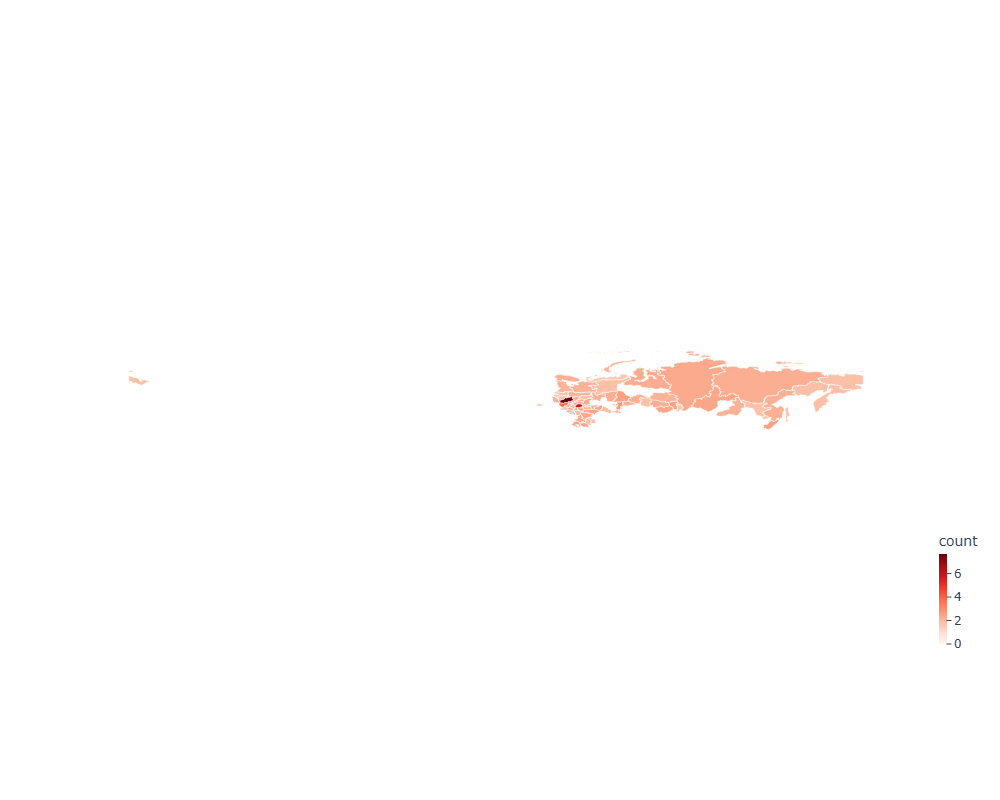

In [24]:
draw_the_map(fold_change)

Вот теперь мы видим, что изменение почти по всем регионам относительно равномерное 

Однако в данный момент мы не рассмотрели самый важный вопрос, который можно решить только по анализу текста, а именно как отделить объявление рабдомов от других постов.

##### **Анализ текстовых признаков**

Гипотеза: **вероятнее всего, (большая) часть постов, которые мы получили, не являются объявлениями рабдомов**.

Данная проблема возникла и на хакатоне, и единственным её решением тогда мы увидели в ручной аннотации датасета на основании критериев рабочего дома: наличия проживания, питания, оплаты труда и общего "вайба" текста.

Для понимания приведём пример "эталонного" объявления рабдома в ВК:

***Дом трудолюбия Урал*** \
*Помощь людям в трудной жизненной ситуаци* \
*Жилье и Питание БЕСПЛАТНО* \
*Денежные выплаты от 1700₽ в день без залоговых и задержек* \
*Телефон +7 (922) 021-27-02 или 8(922) 208-83-69*

На примере данного текста можно увидеть следующие свойства объявления:
- наличие "маркеров рабочего дома": телефона (почти всегда), региона/города (очень часто), ссылка на сайт (иногда), адреса (почти никогда);
- обещание жилья и питания, оплаты труда (обычно в рабдомах предлагают не более 3000 руб), упоминание помощи в трудной жизненной ситуации

При этом текст сам по себе относительно маленький (предполагаем, что в среднем не более 600 символов), есть деление на строки/абзацы

В результате парсинга выделены следующие признаки: 

*text_char_count* - количество символов, \
*text_word_count* - количество слов, \
*text_sentence_count* - количество предложений, \
*text_paragraph_count* - количество параграфов, \
*text_avg_word_length* - средняя длина слова, \
*text_avg_sentence_length* - средняя длина предложения, \
*text_unique_words* - количество уникальных слов, \
*text_unique_word_ratio* - доля уникальных слов, \
*text_url_count* - количество ссылок, \
*text_hashtag_count* - количество хэштегов, \
*text_mention_count* - количество упоминаний по тегу @, \
*text_emoji_count* - количество смайликов, \
*text_digit_count* - количество цифр, \
*text_punctuation_count* - количество знаков пунктуации, \
*text_uppercase_ratio* - доля заглавных символов, \
*text_has_question* - наличие вопросительных знаков (0/1), \
*text_has_exclamation* - наличие восклицательных знаков (0/1), \
*text_is_uppercase* - наличие заглавных букв (0/1), \
*text_has_url* - наличие ссылок (0/1), \
*text_has_hashtag* - наличие хэштегов (0/1), \
*text_has_emoji* - наличие смайликов (0/1)

Для примера возьмём функцию из скрипта text_features_extraction.py и применим её на текст-пример (хотел настроить умный импорт функции, но не смог)

In [25]:
import re

def extract_text_features(text):
    if pd.isna(text):
        text = ""

    text = str(text)

    # Базовая токенизация
    words = re.findall(r'\b\w+\b', text.lower())
    sentences = re.split(r'[.!?]+', text)
    sentences = [s for s in sentences if s.strip()]

    # Символьные признаки
    chars = len(text)
    letters = re.findall(r'[a-zA-Zа-яА-ЯёЁ]', text)
    uppercase = re.findall(r'[A-ZА-ЯЁ]', text)

    # Слова
    word_count = len(words)
    unique_words = len(set(words))

    # Ссылки, хештеги, упоминания
    urls = re.findall(r'https?://\S+|www\.\S+', text)
    hashtags = re.findall(r'#\w+', text)
    mentions = re.findall(r'@\w+', text)

    # Эмодзи (приближённый подсчёт)
    emojis = re.findall(
        r'[\U0001F300-\U0001FAFF'
        r'\U00002600-\U000027BF]',
        text
    )

    return {
        'text_char_count': chars,
        'text_word_count': word_count,
        'text_sentence_count': len(sentences),
        'text_paragraph_count': len(text.splitlines()),
        'text_avg_word_length': (
            sum(map(len, words)) / word_count if word_count else 0
        ),
        'text_avg_sentence_length': (
            word_count / len(sentences) if sentences else 0
        ),
        'text_unique_words': unique_words,
        'text_unique_word_ratio': (
            unique_words / word_count if word_count else 0
        ),
        'text_url_count': len(urls),
        'text_hashtag_count': len(hashtags),
        'text_mention_count': len(mentions),
        'text_emoji_count': len(emojis),
        'text_digit_count': sum(c.isdigit() for c in text),
        'text_punctuation_count': sum(
            not c.isalnum() and not c.isspace() for c in text
        ),
        'text_uppercase_ratio': (
            len(uppercase) / len(letters) if letters else 0
        ),
        'text_has_question': int('?' in text),
        'text_has_exclamation': int('!' in text),
        'text_is_uppercase': int(
            text.isupper() and bool(letters)
        ),
        'text_has_url': int(bool(urls)),
        'text_has_hashtag': int(bool(hashtags)),
        'text_has_emoji': int(bool(emojis)),
    }

In [26]:
example_text = "Дом трудолюбия Урал \n Помощь людям в трудной жизненной ситуации \n Жилье и Питание БЕСПЛАТНО \n Денежные выплаты от 1700₽ в день без залоговых и задержек \n Телефон +7 (922) 021-27-02 или 8(922) 208-83-69 "

extract_text_features(example_text)

{'text_char_count': 202,
 'text_word_count': 35,
 'text_sentence_count': 1,
 'text_paragraph_count': 5,
 'text_avg_word_length': 4.4,
 'text_avg_sentence_length': 35.0,
 'text_unique_words': 32,
 'text_unique_word_ratio': 0.9142857142857143,
 'text_url_count': 0,
 'text_hashtag_count': 0,
 'text_mention_count': 0,
 'text_emoji_count': 0,
 'text_digit_count': 26,
 'text_punctuation_count': 10,
 'text_uppercase_ratio': 0.125,
 'text_has_question': 0,
 'text_has_exclamation': 0,
 'text_is_uppercase': 0,
 'text_has_url': 0,
 'text_has_hashtag': 0,
 'text_has_emoji': 0}

***Дом трудолюбия Урал*** \
*Помощь людям в трудной жизненной ситуации* \
*Жилье и Питание БЕСПЛАТНО* \
*Денежные выплаты от 1700₽ в день без залоговых и задержек* \
*Телефон +7 (922) 021-27-02 или 8(922) 208-83-69*

Уже на основе примера можно предположить, что признаки, связанные с пунктуацией (и, как следствие, с количеством предложений) не совсем верно отображают воспринимаемые человеком величины (потому что в данном тексте можно выделить 4-5 предложений), как и признаки, связанные с наличием и количеством букв в верхнем регистре.

Однако также наши текстовые признаки могут быть созависимыми и/или излишними для дальнейшего анализа, поэтому требуется рассмотрения их характеристик

In [27]:
df_dedupled.columns

Index(['id', 'search_query', 'city', 'region', 'source_type', 'date',
       'author_link', 'link', 'text', 'text_char_count', 'text_word_count',
       'text_sentence_count', 'text_paragraph_count', 'text_avg_word_length',
       'text_avg_sentence_length', 'text_unique_words',
       'text_unique_word_ratio', 'text_url_count', 'text_hashtag_count',
       'text_mention_count', 'text_emoji_count', 'text_digit_count',
       'text_punctuation_count', 'text_uppercase_ratio', 'text_has_question',
       'text_has_exclamation', 'text_is_uppercase', 'text_has_url',
       'text_has_hashtag', 'text_has_emoji'],
      dtype='str')

In [28]:
text_params = ['text_char_count', 'text_word_count',
       'text_sentence_count', 'text_paragraph_count', 'text_avg_word_length',
       'text_avg_sentence_length', 'text_unique_words',
       'text_unique_word_ratio', 'text_url_count', 'text_hashtag_count',
       'text_mention_count', 'text_emoji_count', 'text_digit_count',
       'text_punctuation_count', 'text_uppercase_ratio', 'text_has_question',
       'text_has_exclamation', 'text_is_uppercase', 'text_has_url',
       'text_has_hashtag', 'text_has_emoji']

In [ ]:
sns.pairplot(df[text_params], diag_kind = 'hist', corner = True)
plt.show()

Как мы можем заметить, график огромный и слабо информативный, поэтому стоит разделить текстовые признаки по категориям:
- буквенно-цифровые: *'text_char_count', 'text_word_count', 'text_avg_word_length', 'text_unique_words', 'text_digit_count', 'text_uppercase_ratio'*;
- структурно-текстовые: *'text_sentence_count', 'text_paragraph_count', 'text_avg_sentence_length', 'text_url_count', 'text_hashtag_count', 'text_punctuation_count'*;
- категориальные: *'text_has_question', 'text_has_exclamation', 'text_is_uppercase', 'text_has_url','text_has_hashtag', 'text_has_emoji'*
- другие: *'text_url_count', 'text_hashtag_count', 'text_mention_count', 'text_emoji_count', 'text_digit_count'*

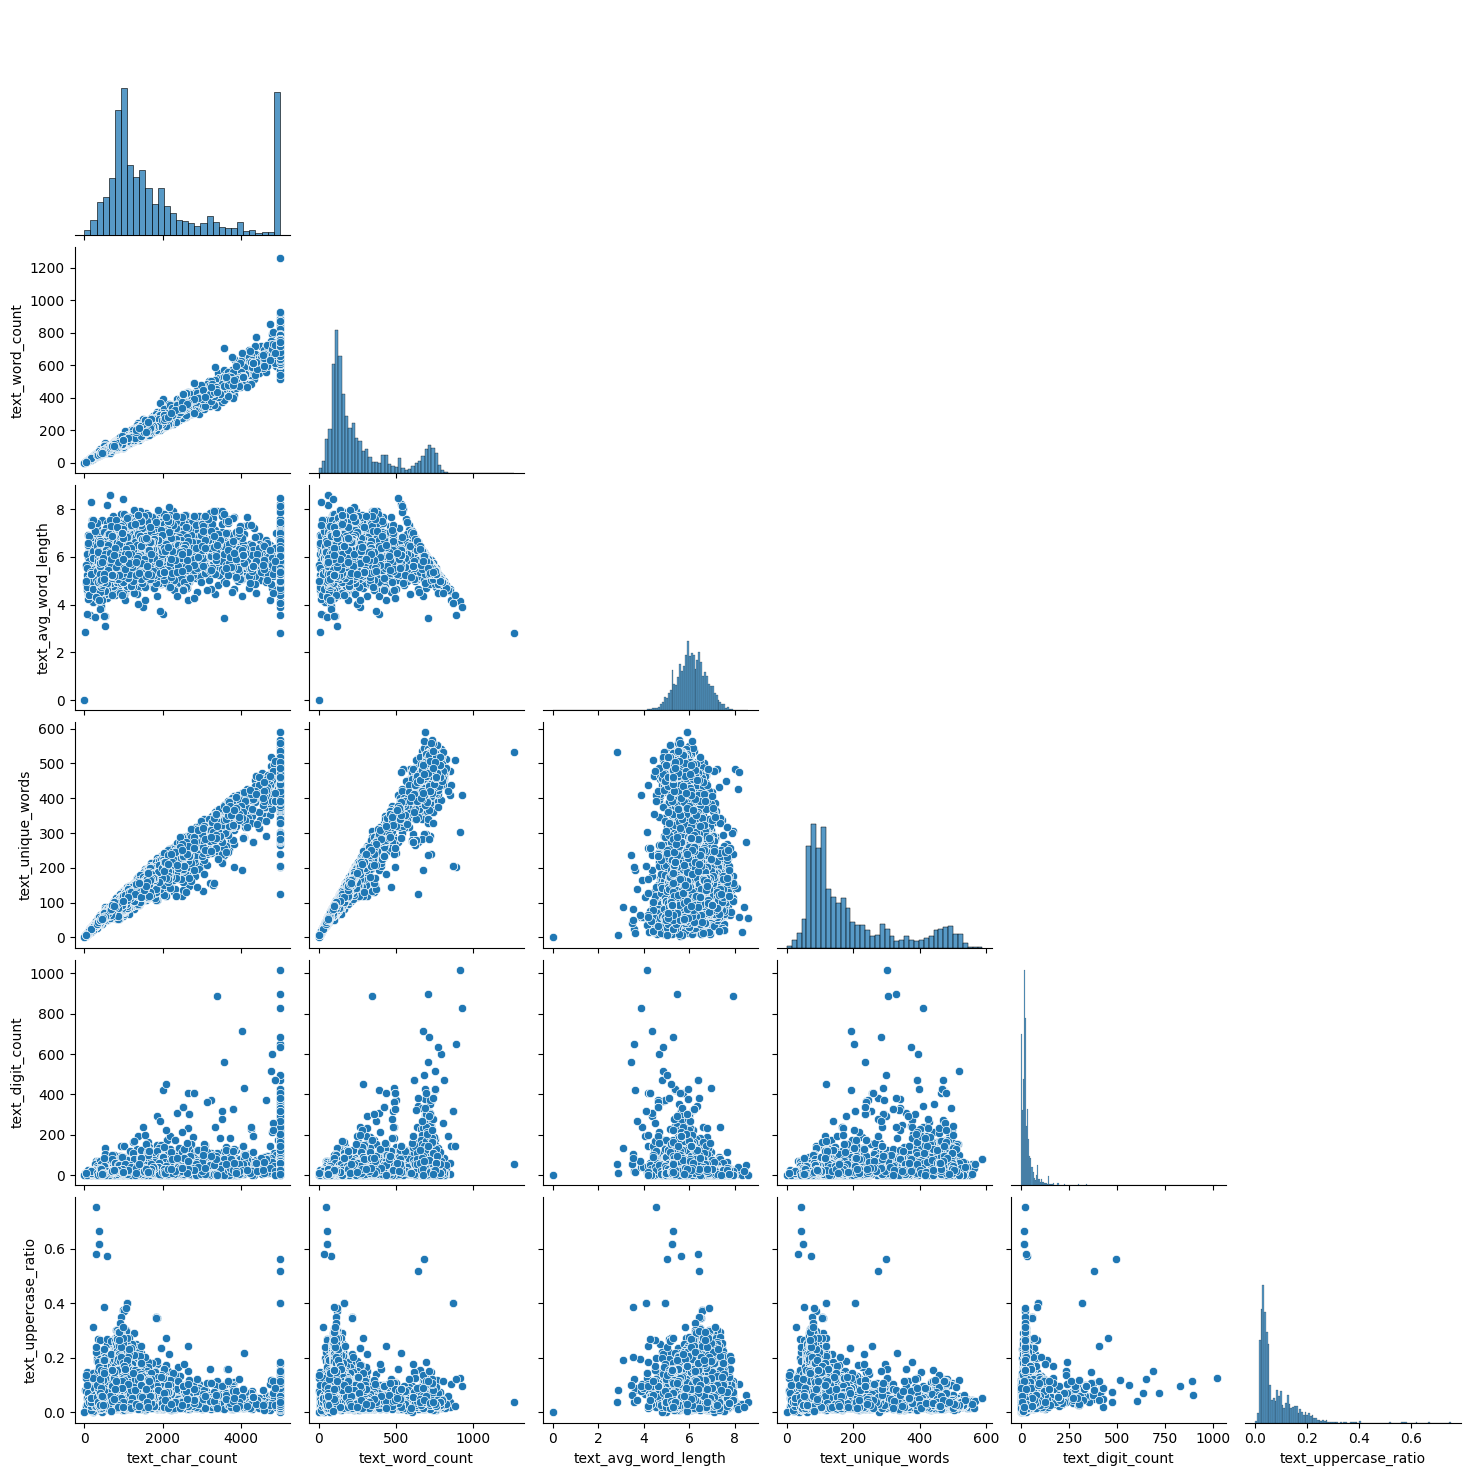

In [ ]:
symbols_params = ['text_char_count', 'text_word_count', 'text_avg_word_length', 'text_unique_words', 'text_digit_count', 'text_uppercase_ratio']
sns.pairplot(df[symbols_params], diag_kind = 'hist', corner = True)
plt.show()

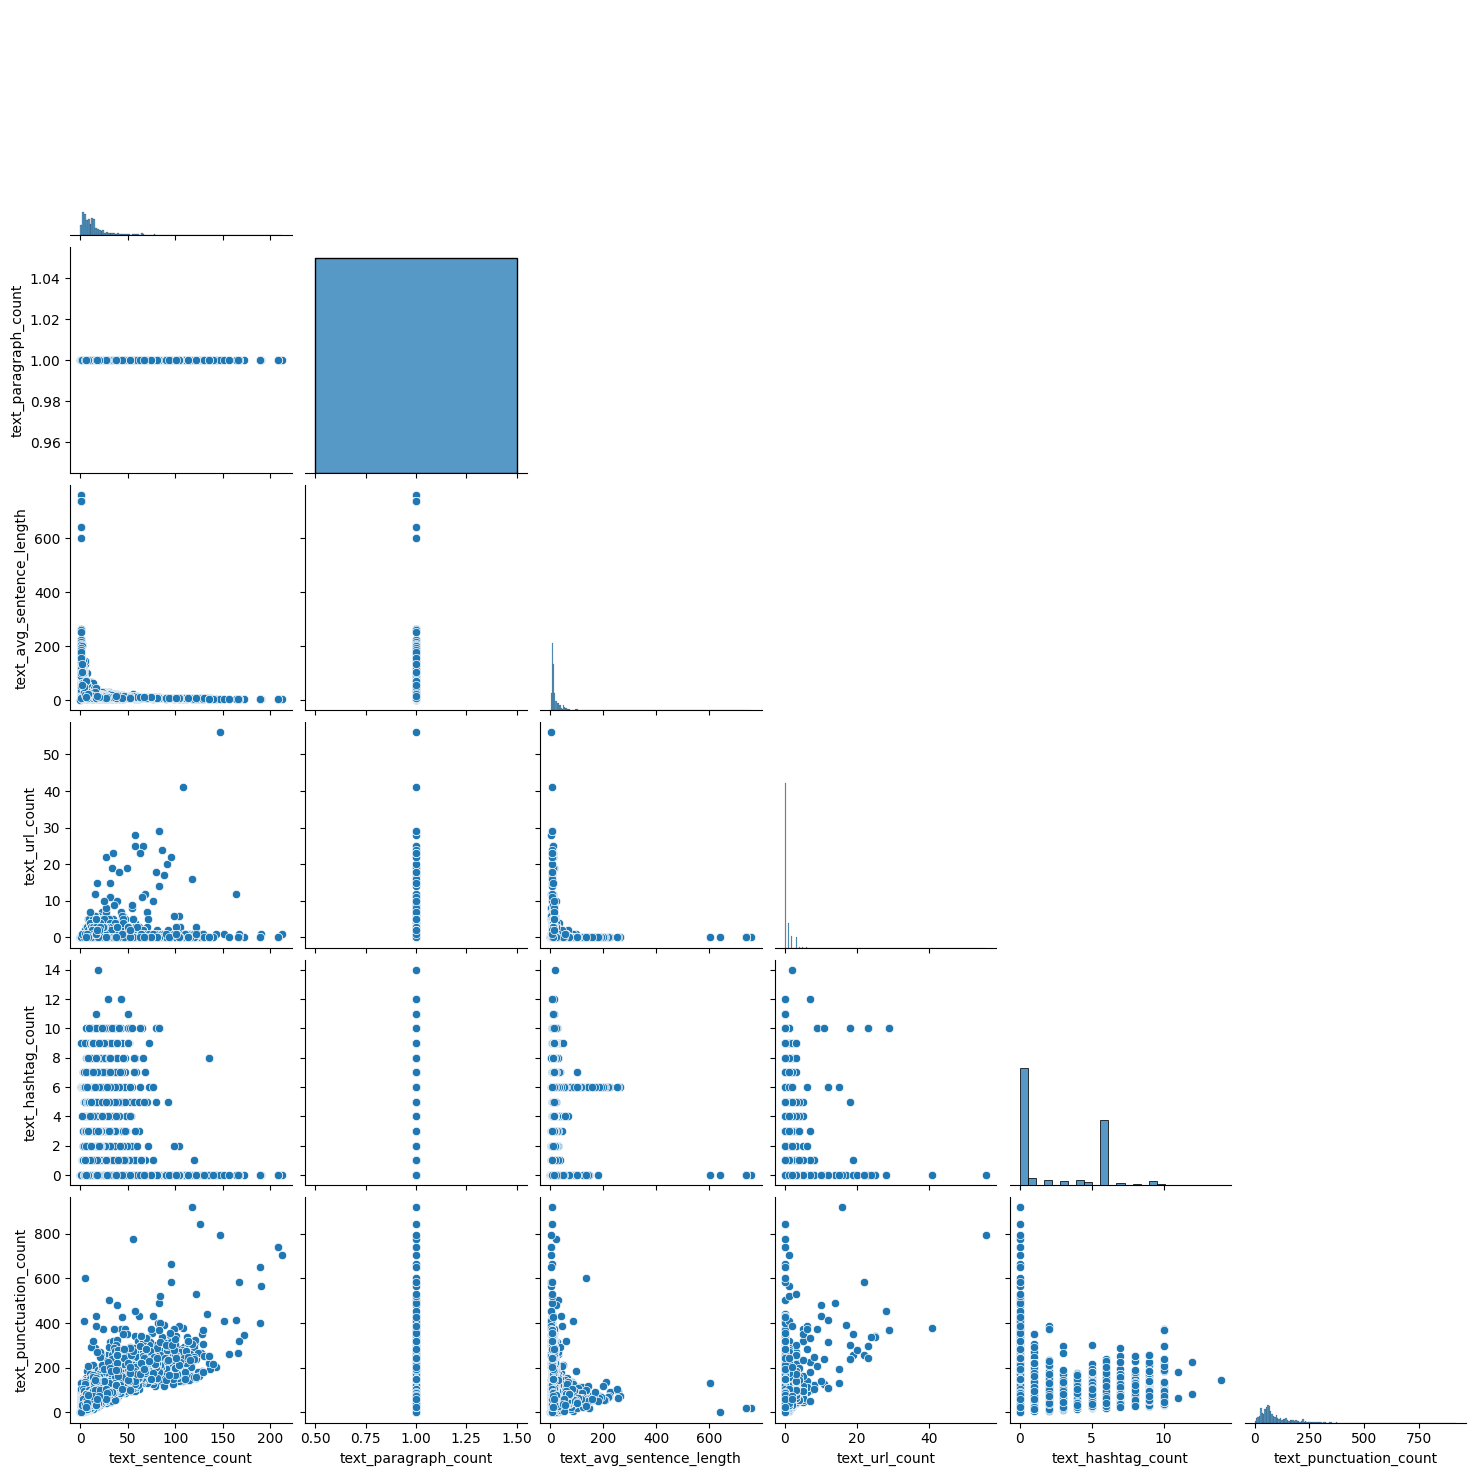

In [ ]:
structure_params = ['text_sentence_count', 'text_paragraph_count', 'text_avg_sentence_length', 'text_url_count', 'text_hashtag_count', 'text_punctuation_count']
sns.pairplot(df[structure_params], diag_kind = 'hist', corner = True)
plt.show()

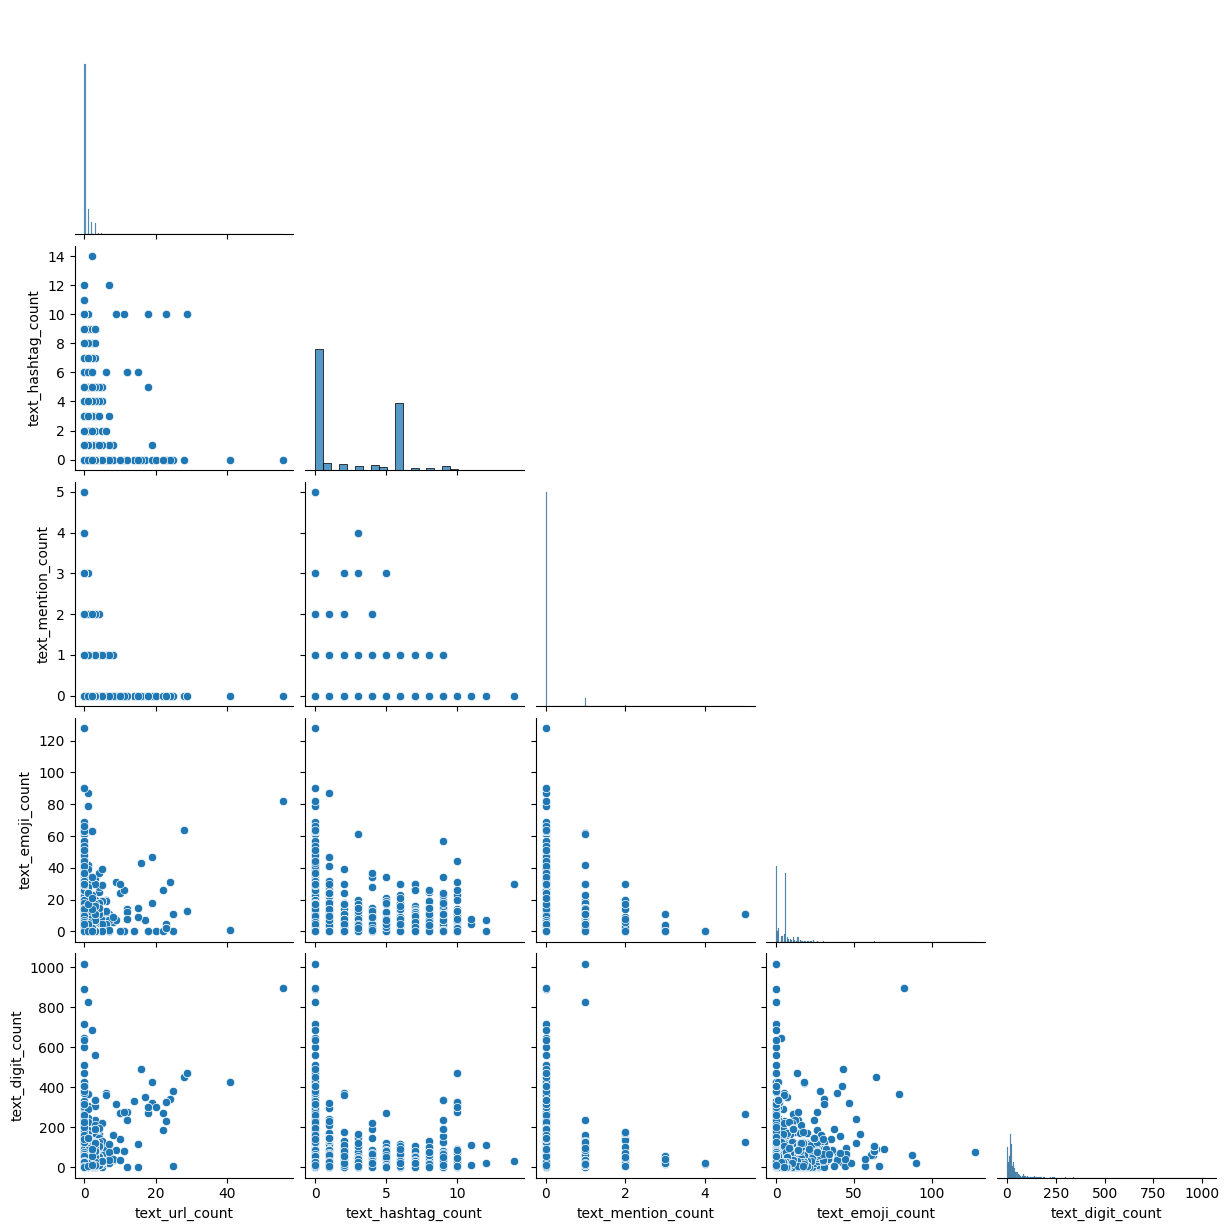

In [38]:
other_params = ['text_url_count', 'text_hashtag_count', 'text_mention_count', 'text_emoji_count', 'text_digit_count']

sns.pairplot(df[other_params], diag_kind = 'hist', corner = True)
plt.show()